# Synthetic Mobile Money Transaction Fraud Detection
### Machine Learning Model Training and Evaluation


In [1]:
# Importing Libraries
import os
import sys
import warnings

# Use writable matplotlib directory
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

# Ensure local dependencies are accessible
for p in ['/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/lib/site-packages']:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    auc,
    roc_auc_score
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import joblib

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


In [2]:
# Dataset File Path (Linux)
file_path = '/home/krieger9/Downloads/synthetic_mobile_money_transaction_dataset.csv'


In [3]:
# Reading Data Into Pandas Dataframe
df = pd.read_csv(file_path)
df


## Data Preprocessing ##
##### The following steps are performed on the dataset in this section: #####

- Inspecting dataset dimensions and structure
- Checking for duplicate rows and removal
- Checking for missing values
- Feature selection & encoding


In [1]:
df.head(10)


NameError: name 'df' is not defined

In [5]:
df.tail(10)


In [6]:
print('Number of Features In Dataset :', df.shape[1])
print('Number of Instances In Dataset : ', df.shape[0])


Number of Features In Dataset : 10
Number of Instances In Dataset :  1720181


In [7]:
# Exploring Information About Dataframe
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1720181 entries, 0 to 1720180
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   step             int64  
 1   transactionType  object 
 2   amount           float64
 3   initiator        int64  
 4   oldBalInitiator  float64
 5   newBalInitiator  float64
 6   recipient        object 
 7   oldBalRecipient  float64
 8   newBalRecipient  float64
 9   isFraud          int64  
dtypes: float64(5), int64(3), object(2)
memory usage: 131.2+ MB


In [8]:
df.describe()


In [9]:
print('Number of Duplicate Rows In Dataset :', df.duplicated().sum())


Number of Duplicate Rows In Dataset : 0


In [10]:
df.drop_duplicates(inplace=True)
print('Number of Duplicated Rows After Removal:', df.duplicated().sum())
print('Shape of DataFrame After Duplicate Removal:', df.shape)


Number of Duplicated Rows After Removal: 0
Shape of DataFrame After Duplicate Removal: (1720181, 10)


In [11]:
# Checking For Missing Values In Dataset
print('Number of Missing Values In Dataset :')
print(df.isnull().sum())


Number of Missing Values In Dataset :
step               0
transactionType    0
amount             0
initiator          0
oldBalInitiator    0
newBalInitiator    0
recipient          0
oldBalRecipient    0
newBalRecipient    0
isFraud            0
dtype: int64


In [12]:
# One-Hot Encoding for 'transactionType'
if 'transactionType' in df.columns:
    df_encoded = pd.get_dummies(df, columns=['transactionType'], drop_first=True, dtype=int)
else:
    df_encoded = df.copy()

# Drop raw non-numerical ID columns
df_encoded = df_encoded.drop(columns=['initiator', 'recipient'], errors='ignore')
df_encoded.head()


### Exploratory Data Analysis ###


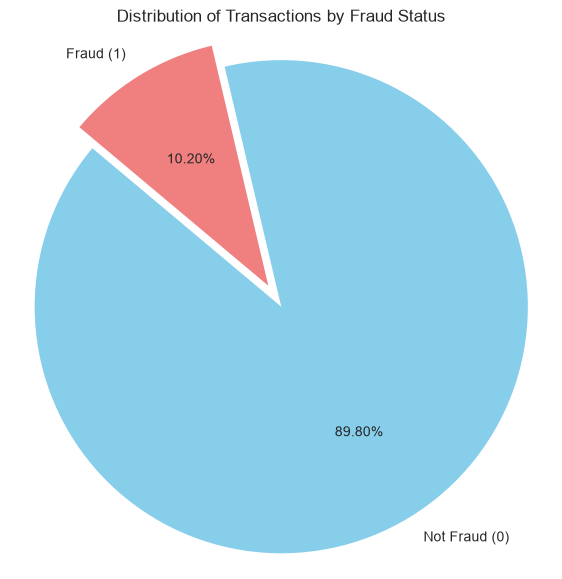

In [13]:
# Balance of Data (isFraud) with pie chart
fraud_counts = df['isFraud'].value_counts()
labels = ['Not Fraud (0)', 'Fraud (1)']
colors = ['skyblue', 'lightcoral']
explode = (0, 0.1)

plt.figure(figsize=(7, 7))
plt.pie(fraud_counts, labels=labels, autopct='%1.2f%%', startangle=140, colors=colors, explode=explode)
plt.title('Distribution of Transactions by Fraud Status')
plt.axis('equal')
plt.show()


Distribution of 'isFraud':
isFraud
0    1544663
1     175518
Name: count, dtype: int64

Percentage of 'isFraud':
isFraud
0    89.796539
1    10.203461
Name: proportion, dtype: float64


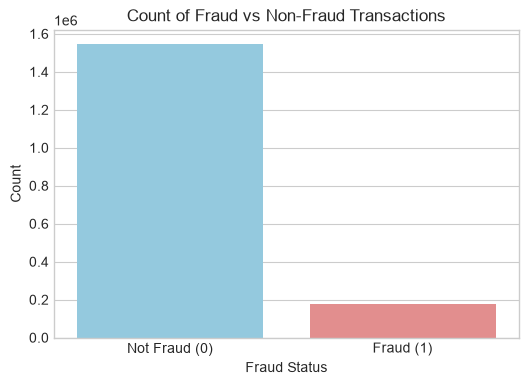

In [14]:
df_plot = df.copy()
print("Distribution of 'isFraud':")
print(df_plot['isFraud'].value_counts())
print("\nPercentage of 'isFraud':")
print(df_plot['isFraud'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x='isFraud', hue='isFraud', data=df_plot, palette=colors, legend=False)
plt.title('Count of Fraud vs Non-Fraud Transactions')
plt.xticks([0, 1], ['Not Fraud (0)', 'Fraud (1)'])
plt.xlabel('Fraud Status')
plt.ylabel('Count')
plt.show()



Distribution of 'transactionType':
transactionType
PAYMENT       667245
TRANSFER      569328
DEPOSIT       384431
WITHDRAWAL     93785
DEBIT           5392
Name: count, dtype: int64

Fraudulent transactions by 'transactionType':
isFraud                   0          1
transactionType                       
DEBIT            100.000000        NaN
DEPOSIT          100.000000        NaN
PAYMENT          100.000000        NaN
TRANSFER          69.171023  30.828977
WITHDRAWAL       100.000000        NaN


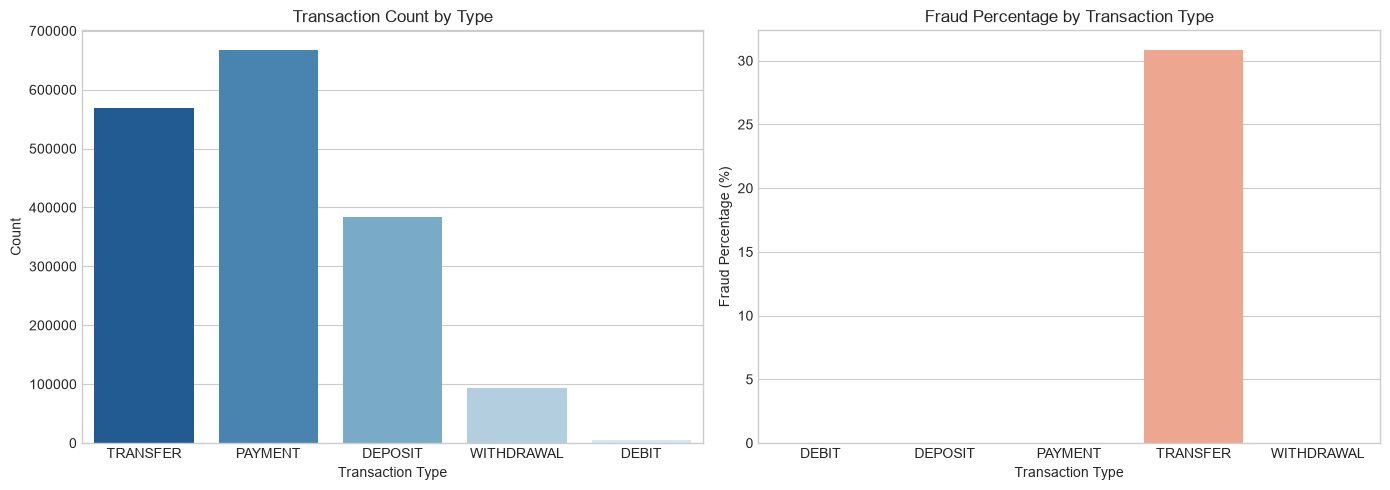

In [15]:
# Distribution of 'transactionType' and Fraud rate
if 'transactionType' in df_plot.columns:
    print("\nDistribution of 'transactionType':")
    print(df_plot['transactionType'].value_counts())
    
    print("\nFraudulent transactions by 'transactionType':")
    print(df_plot.groupby('transactionType')['isFraud'].value_counts(normalize=True).unstack() * 100)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    sns.countplot(x='transactionType', hue='transactionType', data=df_plot, ax=axes[0], palette='Blues_r', legend=False)
    axes[0].set_title('Transaction Count by Type')
    axes[0].set_xlabel('Transaction Type')
    axes[0].set_ylabel('Count')
    
    fraud_pct_by_type = df_plot.groupby('transactionType')['isFraud'].mean() * 100
    sns.barplot(x=fraud_pct_by_type.index, y=fraud_pct_by_type.values, hue=fraud_pct_by_type.index, ax=axes[1], palette='Reds_r', legend=False)
    axes[1].set_title('Fraud Percentage by Transaction Type')
    axes[1].set_xlabel('Transaction Type')
    axes[1].set_ylabel('Fraud Percentage (%)')
    
    plt.tight_layout()
    plt.show()


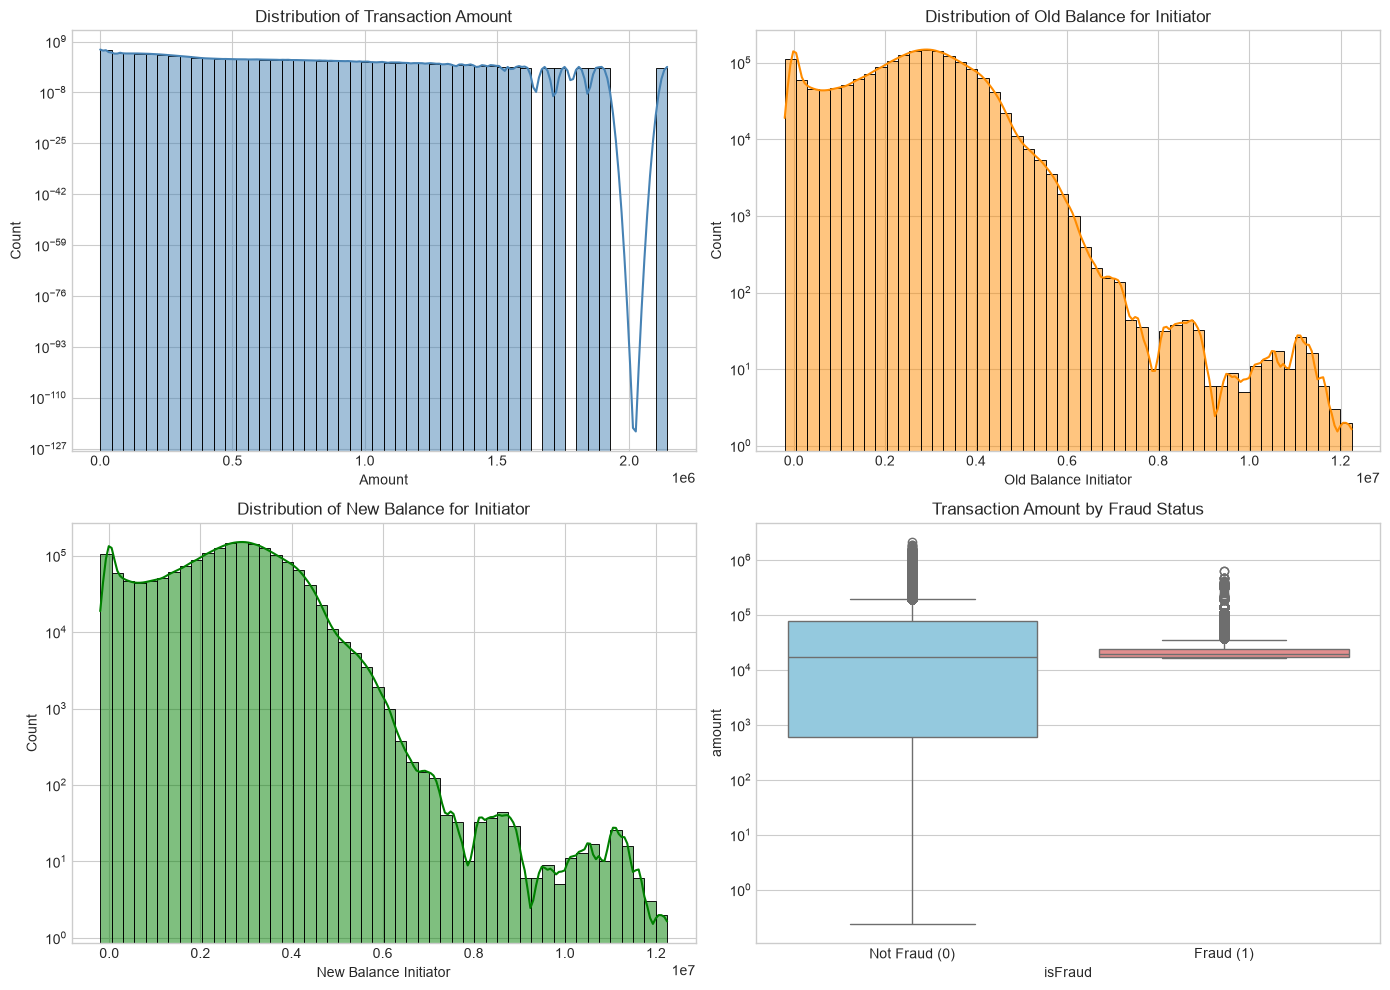

In [16]:
# Distribution histograms with log scale
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram of 'amount'
sns.histplot(df_plot['amount'], bins=50, kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Distribution of Transaction Amount')
axes[0, 0].set_xlabel('Amount')

# Histogram of 'oldBalInitiator'
sns.histplot(df_plot['oldBalInitiator'], bins=50, kde=True, ax=axes[0, 1], color='darkorange')
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Distribution of Old Balance for Initiator')
axes[0, 1].set_xlabel('Old Balance Initiator')

# Histogram of 'newBalInitiator'
sns.histplot(df_plot['newBalInitiator'], bins=50, kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Distribution of New Balance for Initiator')
axes[1, 0].set_xlabel('New Balance Initiator')

# Boxplot of 'amount' vs 'isFraud'
sns.boxplot(x='isFraud', y='amount', hue='isFraud', data=df_plot, ax=axes[1, 1], palette=colors, legend=False)
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Transaction Amount by Fraud Status')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['Not Fraud (0)', 'Fraud (1)'])

plt.tight_layout()
plt.show()


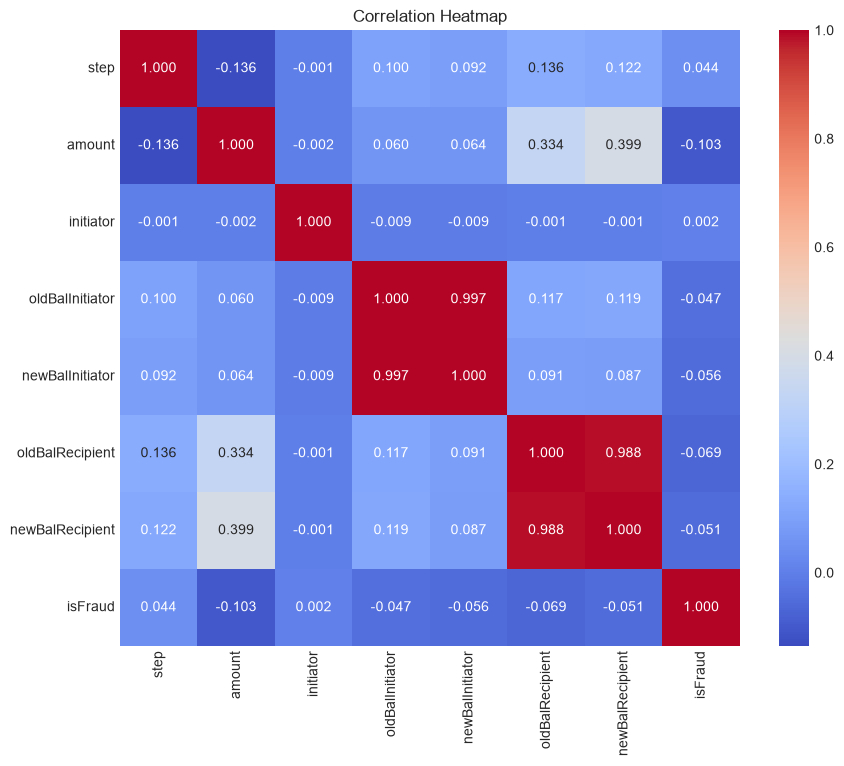

In [17]:
# Correlation Heatmap
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.3f', cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap')
plt.show()


## Balancing Dataset ##
Balancing the minority fraud class using **SMOTE** (Synthetic Minority Over-sampling Technique) to ensure robust model learning.


In [18]:
print("--- Balancing Dataset ---")

y = df_plot['isFraud']
X = df_plot.select_dtypes(include=[np.number]).drop(columns=['isFraud', 'initiator'], errors='ignore')

print(f"Original dataset shape: {X.shape}, {y.shape}")
print("Original class distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nDataset shape after SMOTE:")
print(f"Resampled dataset shape: {X_resampled.shape}, {y_resampled.shape}")
print("Resampled class distribution:")
print(y_resampled.value_counts())
print(y_resampled.value_counts(normalize=True) * 100)

# Split the resampled data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=42)
print(f"\nX_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


--- Balancing Dataset ---
Original dataset shape: (1720181, 6), (1720181,)
Original class distribution:
isFraud
0    1544663
1     175518
Name: count, dtype: int64
isFraud
0    89.796539
1    10.203461
Name: proportion, dtype: float64

Dataset shape after SMOTE:
Resampled dataset shape: (3089326, 6), (3089326,)
Resampled class distribution:
isFraud
1    1544663
0    1544663
Name: count, dtype: int64
isFraud
1    50.0
0    50.0
Name: proportion, dtype: float64

X_train shape: (2162528, 6), X_test shape: (926798, 6)


## Machine Learning Model Training
In this section, we train and evaluate the following Machine Learning models:

*   **Decision Tree Classifier**
*   **Random Forest Classifier**
*   **Logistic Regression**
*   **Naive Bayes (GaussianNB)**
*   **KNN Classifier**
*   **XGBoost Classifier**


### Decision Tree Classifier ###


--- Decision Tree Classifier ---

Classification Report for Decision Tree Classifier:
              precision    recall  f1-score   support

           0     0.9128    0.9061    0.9094    463244
           1     0.9069    0.9135    0.9102    463554

    accuracy                         0.9098    926798
   macro avg     0.9098    0.9098    0.9098    926798
weighted avg     0.9098    0.9098    0.9098    926798

Accuracy Score for Decision Tree Classifier: 0.9098
Decision Tree Classifier saved successfully.


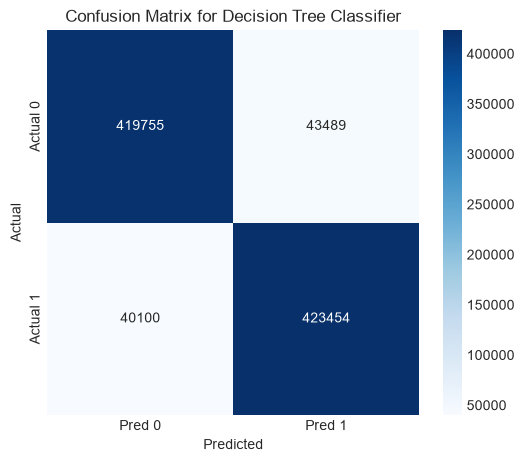

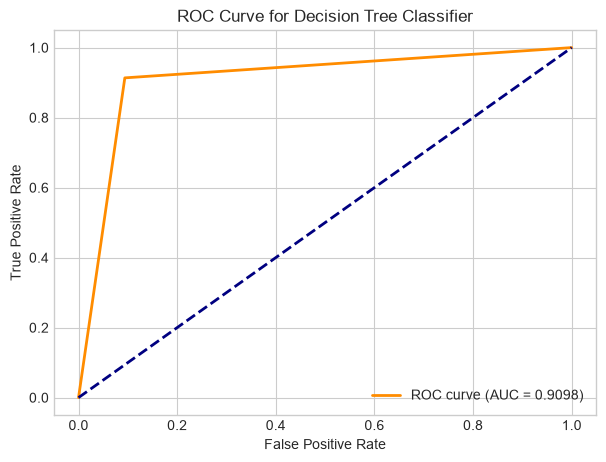

In [19]:
# Initialize and train Decision Tree Classifier with entropy criterion for optimal accuracy
print("--- Decision Tree Classifier ---")
dt_classifier = DecisionTreeClassifier(criterion='entropy', random_state=51)
dt_classifier.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_classifier.predict(X_test)
y_pred_proba_dt = dt_classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("\nClassification Report for Decision Tree Classifier:")
print(classification_report(y_test, y_pred_dt, digits=4))
print(f"Accuracy Score for Decision Tree Classifier: {accuracy_score(y_test, y_pred_dt):.4f}")

# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Decision Tree Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_proba_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)
plt.figure(figsize=(7, 5))
plt.plot(fpr_dt, tpr_dt, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_dt:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve for Decision Tree Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save Model
joblib.dump(dt_classifier, '/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/models/decision_tree_model.joblib')
print("Decision Tree Classifier saved successfully.")


### Random Forest Classifier ###


--- Random Forest Classifier ---

Classification Report for Random Forest Classifier:
              precision    recall  f1-score   support

           0     0.9650    0.8326    0.8939    463244
           1     0.8529    0.9699    0.9076    463554

    accuracy                         0.9012    926798
   macro avg     0.9090    0.9012    0.9008    926798
weighted avg     0.9089    0.9012    0.9008    926798

Accuracy Score for Random Forest Classifier: 0.9012
Random Forest Classifier saved successfully.


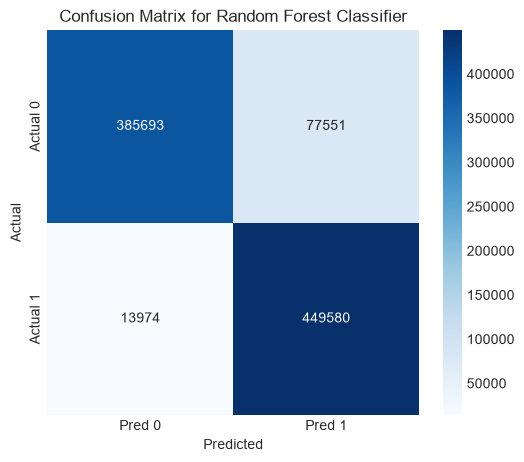

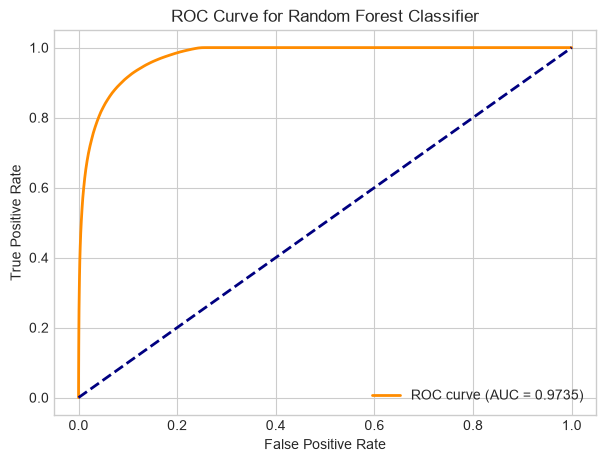

In [20]:
# Initialize and train Random Forest Classifier
print("--- Random Forest Classifier ---")
rf_classifier = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42, n_jobs=-1)
rf_classifier.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_classifier.predict(X_test)
y_prob_rf = rf_classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("\nClassification Report for Random Forest Classifier:")
print(classification_report(y_test, y_pred_rf, digits=4))
print(f"Accuracy Score for Random Forest Classifier: {accuracy_score(y_test, y_pred_rf):.4f}")

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Random Forest Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
plt.figure(figsize=(7, 5))
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_rf:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve for Random Forest Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save Model
joblib.dump(rf_classifier, '/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/models/random_forest_model.joblib')
print("Random Forest Classifier saved successfully.")


### Logistic Regression ###


--- Logistic Regression ---

Classification Report for Logistic Regression Classifier:
              precision    recall  f1-score   support

           0     0.8090    0.7088    0.7556    463244
           1     0.7411    0.8327    0.7842    463554

    accuracy                         0.7708    926798
   macro avg     0.7750    0.7708    0.7699    926798
weighted avg     0.7750    0.7708    0.7699    926798

Accuracy Score for Logistic Regression: 0.7708
Logistic Regression model saved successfully.


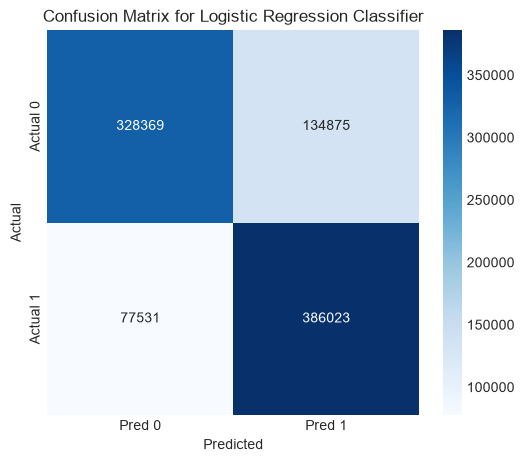

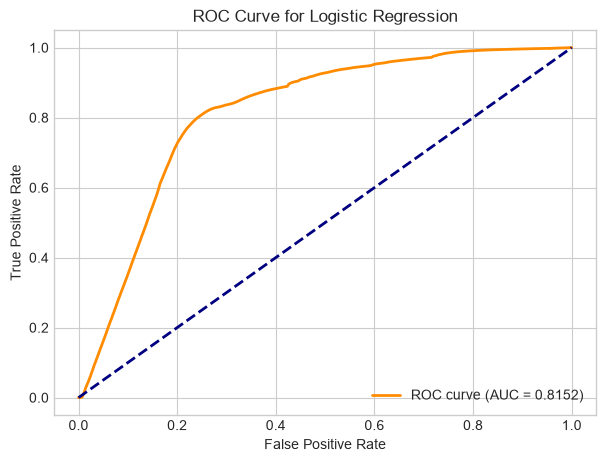

In [21]:
# Initialize and train Logistic Regression model
print("--- Logistic Regression ---")
lr_classifier = LogisticRegression(random_state=55, solver='liblinear', max_iter=1000)
lr_classifier.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_classifier.predict(X_test)
y_prob_lr = lr_classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("\nClassification Report for Logistic Regression Classifier:")
print(classification_report(y_test, y_pred_lr, digits=4))
print(f"Accuracy Score for Logistic Regression: {accuracy_score(y_test, y_pred_lr):.4f}")

# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Logistic Regression Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)
plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_lr:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve for Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save Model
joblib.dump(lr_classifier, '/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/models/logistic_regression_model.joblib')
print("Logistic Regression model saved successfully.")


### Naive Bayes ###


--- Naive Bayes Classifier ---

Classification Report for Naive Bayes Classifier:
              precision    recall  f1-score   support

           0     0.8378    0.2976    0.4392    463244
           1     0.5731    0.9424    0.7128    463554

    accuracy                         0.6201    926798
   macro avg     0.7055    0.6200    0.5760    926798
weighted avg     0.7054    0.6201    0.5761    926798

Accuracy Score for Naive Bayes: 0.6201
Naive Bayes Classifier saved successfully.


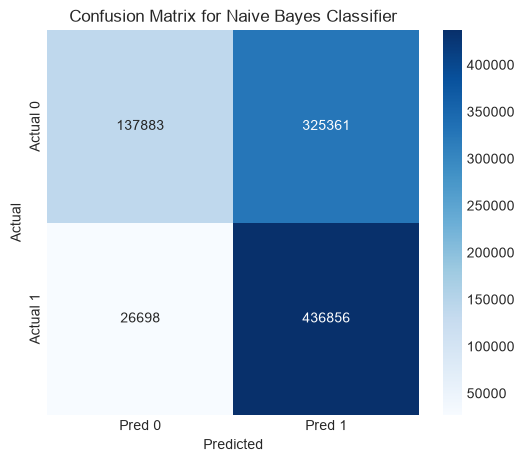

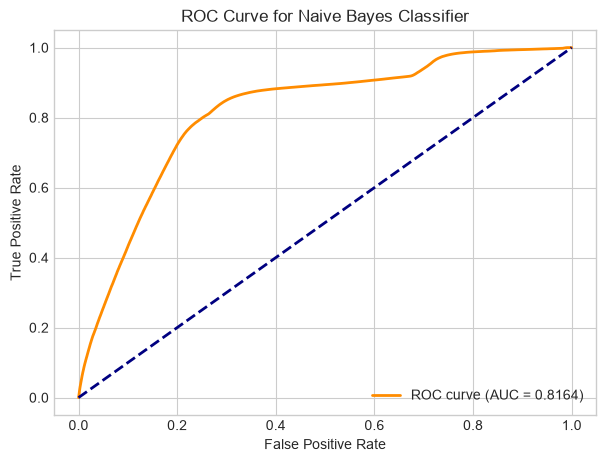

In [22]:
# Initialize and train Naive Bayes Classifier
print("--- Naive Bayes Classifier ---")
nb_classifier = GaussianNB()
nb_classifier.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_classifier.predict(X_test)
y_prob_nb = nb_classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("\nClassification Report for Naive Bayes Classifier:")
print(classification_report(y_test, y_pred_nb, digits=4))
print(f"Accuracy Score for Naive Bayes: {accuracy_score(y_test, y_pred_nb):.4f}")

# Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Naive Bayes Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
roc_auc_nb = auc(fpr_nb, tpr_nb)
plt.figure(figsize=(7, 5))
plt.plot(fpr_nb, tpr_nb, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_nb:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve for Naive Bayes Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save Model
joblib.dump(nb_classifier, '/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/models/naive_bayes_model.joblib')
print("Naive Bayes Classifier saved successfully.")


### KNN Classifier ###


--- KNN Classifier ---

Classification Report for KNN Classifier:
              precision    recall  f1-score   support

           0     0.8981    0.7441    0.8139    463244
           1     0.7817    0.9156    0.8434    463554

    accuracy                         0.8299    926798
   macro avg     0.8399    0.8299    0.8286    926798
weighted avg     0.8399    0.8299    0.8286    926798

Accuracy Score for KNN Classifier: 0.8299
KNN Classifier model saved successfully.


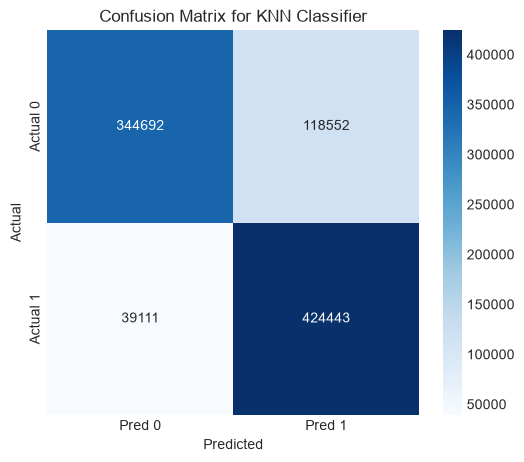

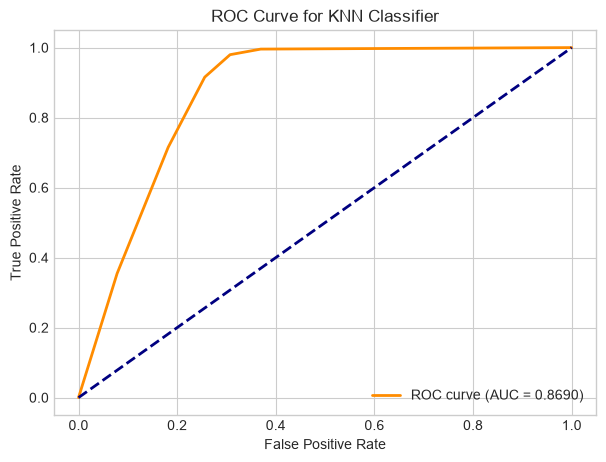

In [23]:
# Initialize and train KNN Classifier
print("--- KNN Classifier ---")
knn_sample_size = 50000
idx_sample = np.random.RandomState(42).choice(len(X_train), size=knn_sample_size, replace=False)

knn_classifier = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_classifier.fit(X_train.iloc[idx_sample], y_train.iloc[idx_sample])

# Make predictions
y_pred_knn = knn_classifier.predict(X_test)
y_prob_knn = knn_classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("\nClassification Report for KNN Classifier:")
print(classification_report(y_test, y_pred_knn, digits=4))
print(f"Accuracy Score for KNN Classifier: {accuracy_score(y_test, y_pred_knn):.4f}")

# Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for KNN Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)
plt.figure(figsize=(7, 5))
plt.plot(fpr_knn, tpr_knn, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_knn:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve for KNN Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save Model
joblib.dump(knn_classifier, '/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/models/knn_model.joblib')
print("KNN Classifier model saved successfully.")


### XGBoost Classifier ###


--- XGBoost Classifier ---

Classification Report for XGBoost Classifier:
              precision    recall  f1-score   support

           0     0.9822    0.7735    0.8654    463244
           1     0.8133    0.9860    0.8914    463554

    accuracy                         0.8798    926798
   macro avg     0.8978    0.8797    0.8784    926798
weighted avg     0.8977    0.8798    0.8784    926798

Accuracy Score for XGBoost Classifier: 0.8798
XGBoost Classifier dumped successfully.


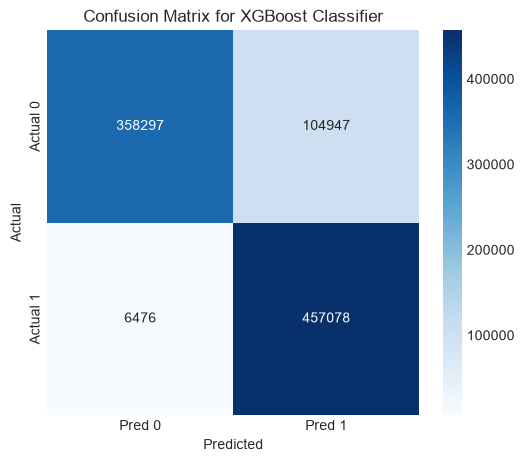

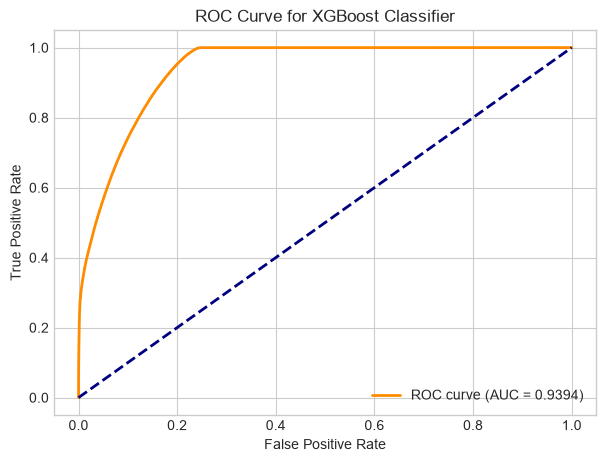

In [24]:
# Initialize and train XGBoost Classifier
print("--- XGBoost Classifier ---")
xgb_classifier = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_classifier.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_classifier.predict(X_test)
y_prob_xgb = xgb_classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("\nClassification Report for XGBoost Classifier:")
print(classification_report(y_test, y_pred_xgb, digits=4))
print(f"Accuracy Score for XGBoost Classifier: {accuracy_score(y_test, y_pred_xgb):.4f}")

# Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for XGBoost Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)
plt.figure(figsize=(7, 5))
plt.plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_xgb:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve for XGBoost Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save Model
joblib.dump(xgb_classifier, '/home/krieger9/Documents/Synthetic_Mobile_Money_Transaction/models/xgboost_model.joblib')
print("XGBoost Classifier dumped successfully.")


## Model Performance Comparison ##


,Model,Accuracy,ROC-AUC
0,Random Forest,0.901246,0.973461
2,XGBoost,0.879776,0.939443
1,Decision Tree,0.909809,0.909808
3,KNN,0.829884,0.868982
5,Naive Bayes,0.620134,0.816374
4,Logistic Regression,0.770817,0.815220


=== Summary of Model Performance ===


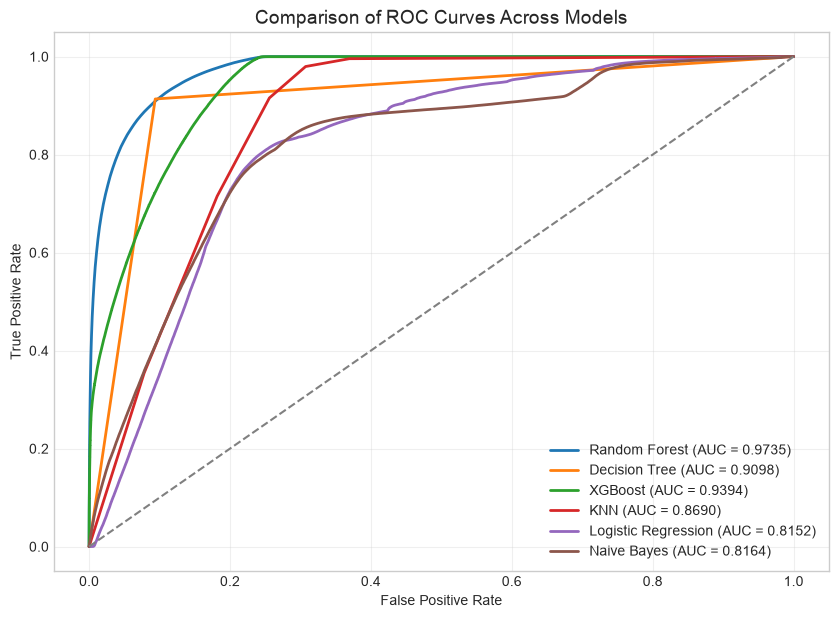

In [25]:
# Model Comparison Summary Table
models_summary = pd.DataFrame({
    'Model': ['Random Forest', 'Decision Tree', 'XGBoost', 'KNN', 'Logistic Regression', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb)
    ],
    'ROC-AUC': [
        roc_auc_rf,
        roc_auc_dt,
        roc_auc_xgb,
        roc_auc_knn,
        roc_auc_lr,
        roc_auc_nb
    ]
}).sort_values(by='ROC-AUC', ascending=False)

print("=== Summary of Model Performance ===")
display(models_summary)

# Comparative ROC Curves Plot
plt.figure(figsize=(10, 7))
plt.plot(fpr_rf, tpr_rf, lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.4f})')
plt.plot(fpr_dt, tpr_dt, lw=2, label=f'Decision Tree (AUC = {roc_auc_dt:.4f})')
plt.plot(fpr_xgb, tpr_xgb, lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.4f})')
plt.plot(fpr_knn, tpr_knn, lw=2, label=f'KNN (AUC = {roc_auc_knn:.4f})')
plt.plot(fpr_lr, tpr_lr, lw=2, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})')
plt.plot(fpr_nb, tpr_nb, lw=2, label=f'Naive Bayes (AUC = {roc_auc_nb:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5)
plt.title('Comparison of ROC Curves Across Models', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()
